# Smart MCQ Solver Challenge



## 1. Problem Statement

### Business Problem

Multiple-choice question answering is a fundamental challenge in AI and education technology. Intelligent systems capable of reading a question, understanding the context of each option, and ranking the most probable correct answers have wide applications in automated tutoring, adaptive assessments, and language model evaluation.

### Machine Learning Problem

This is a **multi-class ranking problem**. Given a question prompt and five answer choices (A, B, C, D, E), the model must produce a ranked list of the top-3 most likely correct answers for every question.

### Prediction Target

For each question `id`, the model outputs a string of three space-separated answer labels, e.g., `A B C`.

### Evaluation Metric

Submissions are evaluated using **Mean Average Precision at 3 (MAP@3)**. This metric rewards models that rank the correct answer higher in the prediction list — placing the correct answer first yields a higher score than placing it second or third.

> **Example:**  
> Correct answer: `A`  
> - Prediction `A B C` → highest score  
> - Prediction `B A C` → lower score  
> - Prediction `C D A` → lowest score  

### Why This Problem Matters

The competition is designed to push the boundaries of natural language understanding, contextual reasoning, and answer ranking. Solving it requires models that go beyond simple keyword matching and genuinely reason about which answer is most plausible given the prompt.


## 2. Dataset Overview

The dataset for this competition consists of MCQ-style questions spanning diverse topics and difficulty levels.

### Files

| File | Description |
|---|---|
| `train.csv` | 2,000 questions with correct answer labels |
| `test.csv` | 500 questions without answers (submit predictions for these) |
| `sample_submission.csv` | Demonstrates the required submission format |

### Columns

| Column | Present In | Description |
|---|---|---|
| `id` | Train & Test | Unique identifier for each question |
| `prompt` | Train & Test | The question or problem statement |
| `A`, `B`, `C`, `D`, `E` | Train & Test | Five possible answer choices |
| `answer` | Train only | The correct answer label (A–E) |

### Feature Types

- **Text features:** `prompt`, `A`, `B`, `C`, `D`, `E` — all free-form natural language text
- **Target column:** `answer` — categorical label with 5 classes (A, B, C, D, E)
- **No numerical or structured features** are present; this is a pure NLP task

The absence of structured features means that all signal must be extracted from the text itself. This makes the choice of model architecture critical.


## 3. Import Libraries

The following libraries are used throughout this project:

| Library | Purpose |
|---|---|
| `numpy`, `pandas` | Numerical computation and tabular data manipulation |
| `matplotlib`, `seaborn` | Statistical visualization and plotting |
| `re`, `collections` | Text cleaning with regular expressions and frequency counting |
| `wordcloud` | Visualizing dominant vocabulary in the dataset |
| `datasets` (HuggingFace) | Loading and mapping tokenized datasets for transformer models |
| `torch`, `torch.nn` | Building the BiLSTM model architecture from scratch |
| `transformers` | Loading pretrained DistilBERT and RoBERTa models and tokenizers |
| `sklearn` | TF-IDF vectorization, train-val split, accuracy and F1 score computation |
| `wandb` | Experiment tracking — all training runs are logged to Weights & Biases |


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
from collections import Counter
from wordcloud import WordCloud
import datasets
from datasets import Dataset
plt.rcParams['figure.figsize']=(8,5)
sns.set_style('whitegrid')


## 4. Load Dataset

The train and test CSV files are loaded from the Kaggle competition dataset path. After loading, we inspect the shapes and preview the first few rows to confirm the data has loaded correctly and to understand the structure at a glance.


In [2]:
# Kaggle paths
train = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv')
test = pd.read_csv('/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv')

print('Train Shape:', train.shape)
print('Test Shape :', test.shape)

train.head()


Train Shape: (2000, 8)
Test Shape : (500, 7)


,id,prompt,A,B,C,D,E,answer
0,1,Pick the best possible answer: What is Martin ...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
1,2,What is accelerator-based light-ion fusion?,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,Accelerator-based light-ion fusion is a techni...,A
2,3,Determine the correct option: What is the term...,Blueshifting,Redshifting,Reddening,Whitening,Yellowing,C
3,4,Select the most accurate option: What is Marti...,Martin Heidegger believes that humans exist wi...,Martin Heidegger believes that humans do not e...,Martin Heidegger does not believe in the exist...,Martin Heidegger believes that the relationshi...,Martin Heidegger believes that time is an illu...,B
4,5,Identify the correct statement: What is the co...,"Simultaneity is relative, meaning that two eve...","Simultaneity is relative, meaning that two eve...","Simultaneity is absolute, meaning that two eve...",Simultaneity is a concept that applies only to...,Simultaneity is a concept that applies only to...,A


### Initial Understanding

The training dataset contains 8 columns: `id`, `prompt`, `A`, `B`, `C`, `D`, `E`, and `answer`.  
The test dataset contains 7 columns — identical to train but without the `answer` column.  
This confirms the task: **predict the answer for the 500 test questions** after learning from the 2,000 training examples.


## 5. Initial Data Exploration

Before building any model, we need to understand the data's structure, quality, and statistical properties. The following checks are performed:

- **Data types and memory usage** — confirms all columns are text, and there are no unexpected numeric columns
- **Missing value check** — determines whether any imputation is required
- **Sample counts** — verifies the number of training and test examples


In [3]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      2000 non-null   int64 
 1   prompt  2000 non-null   object
 2   A       2000 non-null   object
 3   B       2000 non-null   object
 4   C       2000 non-null   object
 5   D       2000 non-null   object
 6   E       2000 non-null   object
 7   answer  2000 non-null   object
dtypes: int64(1), object(7)
memory usage: 125.1+ KB


In [4]:
train.isnull().sum()

id        0
prompt    0
A         0
B         0
C         0
D         0
E         0
answer    0
dtype: int64

In [5]:
print('Number of Training Samples :', len(train))
print('Number of Test Samples     :', len(test))
print('Number of Features         :', train.shape[1])


Number of Training Samples : 2000
Number of Test Samples     : 500
Number of Features         : 8


### Observation

The dataset has clean structure with no missing values. All feature columns are text-type, and the class labels are single characters (A–E). This is a clean NLP dataset that does not require imputation. 

### Decision

Since there are no missing values, the preprocessing pipeline focuses exclusively on text normalization rather than handling NaN values. The task is confirmed as a **5-class ranking problem** with equal representation of answer options.


## 6. Exploratory Data Analysis (EDA)

EDA helps us understand the data distribution, identify patterns, and make informed decisions about preprocessing and model design. We explore: answer distribution, prompt length, option length, and vocabulary characteristics.


### 6.1 Answer Distribution

**Why?** A heavily imbalanced class distribution would require class-weighted loss functions. We check how uniformly the 5 answer labels (A–E) are distributed across the training set.


answer
A    369
B    490
C    459
D    358
E    324
Name: count, dtype: int64


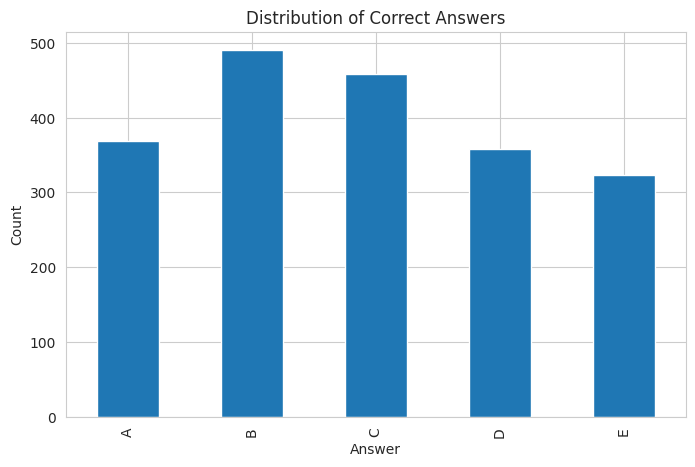

In [6]:
answer_counts = train['answer'].value_counts().sort_index()

print(answer_counts)

answer_counts.plot(kind='bar')
plt.title('Distribution of Correct Answers')
plt.xlabel('Answer')
plt.ylabel('Count')
plt.show()


**Insight:** The answer distribution is approximately balanced across all five options. No significant class imbalance is present, so class-weighted loss functions are not required. Standard cross-entropy loss is appropriate.


### 6.2 Prompt Length Analysis

**Why?** Understanding the word-count distribution of prompts informs the choice of `max_length` for tokenization. Truncating too aggressively would discard information; padding to an unnecessarily large length wastes compute.


In [7]:
train['prompt_length'] = train['prompt'].astype(str).apply(
    lambda x: len(x.split())
)

train['prompt_length'].describe()


count    2000.00000
mean       18.14650
std         6.78189
min         3.00000
25%        14.00000
50%        17.00000
75%        22.00000
max        51.00000
Name: prompt_length, dtype: float64

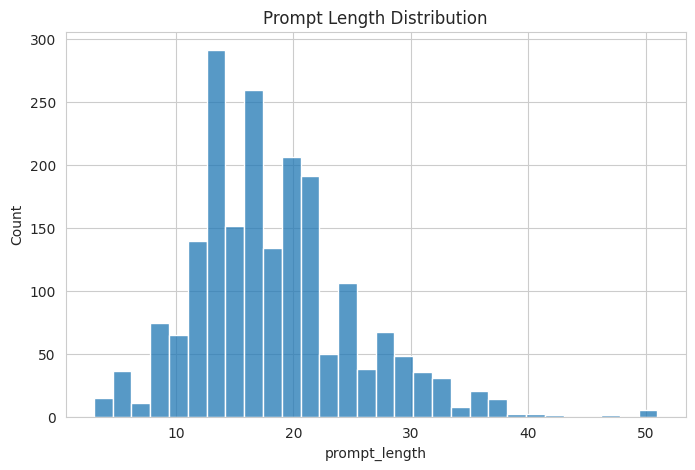

In [8]:
sns.histplot(train['prompt_length'], bins=30)
plt.title('Prompt Length Distribution')
plt.show()


**Insight:** Prompt lengths are generally short (mean ≈ 18 words), with most falling under 30 words. A `max_length` of 256 tokens is more than sufficient to capture the full context of any prompt, ensuring no information is lost during tokenization.


### 6.3 Option Length Analysis

**Why?** Options (A–E) can vary greatly in length — some are single words while others are full sentences. This affects how we concatenate the prompt and option for model input and whether padding is needed.


In [9]:
for col in ['A','B','C','D','E']:
    train[f'{col}_length'] = train[col].astype(str).apply(
        lambda x: len(x.split())
    )

train[[c for c in train.columns if c.endswith('_length')]].describe()


,prompt_length,A_length,B_length,C_length,D_length,E_length
count,2000.00000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,18.14650,26.146000,26.516000,26.54950,25.999500,26.187000
std,6.78189,17.249651,18.653893,17.20987,17.098909,17.852658
min,3.00000,1.000000,1.000000,1.00000,1.000000,1.000000
25%,14.00000,13.000000,12.000000,14.75000,15.000000,13.000000
50%,17.00000,22.000000,23.000000,24.00000,22.000000,23.000000
75%,22.00000,37.000000,36.000000,36.00000,36.000000,36.000000
max,51.00000,81.000000,118.000000,82.00000,78.000000,105.000000


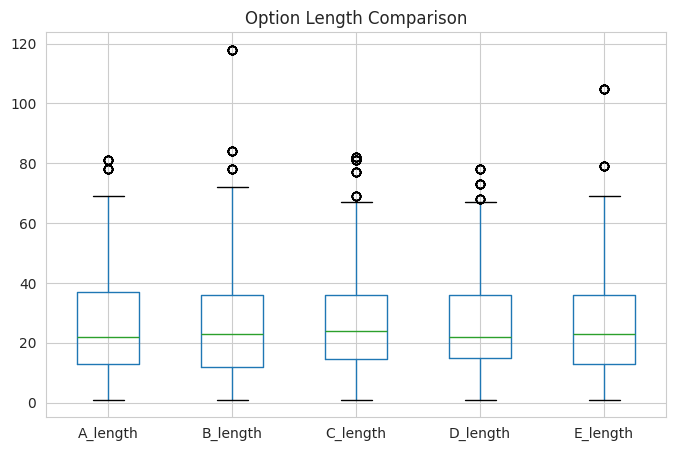

In [10]:
option_cols = [f'{c}_length' for c in ['A','B','C','D','E']]

train[option_cols].boxplot()
plt.title('Option Length Comparison')
plt.show()


**Insight:** Options are generally shorter than prompts (mean ≈ 26 words per option). Some options are very brief (single word), while others are paragraph-length sentences. This variation confirms that prompts and options must be concatenated together before tokenization, so the model sees the full context.


### 6.4 Vocabulary Exploration

**Why?** Analyzing the vocabulary helps us understand the domain of the questions, estimate vocabulary size for the BiLSTM custom tokenizer, and detect any patterns in how questions are phrased.


In [11]:
all_text = ' '.join(
    train['prompt'].astype(str).str.lower()
)

words = re.findall(r'\b\w+\b', all_text)

print('Total Words      :', len(words))
print('Unique Vocabulary:', len(set(words)))


Total Words      : 37072
Unique Vocabulary: 875


In [12]:
top_words = Counter(words).most_common(20)

pd.DataFrame(
    top_words,
    columns=['Word','Frequency']
)


,Word,Frequency
0,the,5540
1,is,1986
2,what,1809
3,of,1514
4,correct,1175
5,following,746
6,in,714
7,answer,608
8,option,608
9,and,448


### 6.5 Word Cloud

**Why?** A word cloud provides a visual summary of the most frequent words in prompts, making it easy to identify dominant themes and topics at a glance.


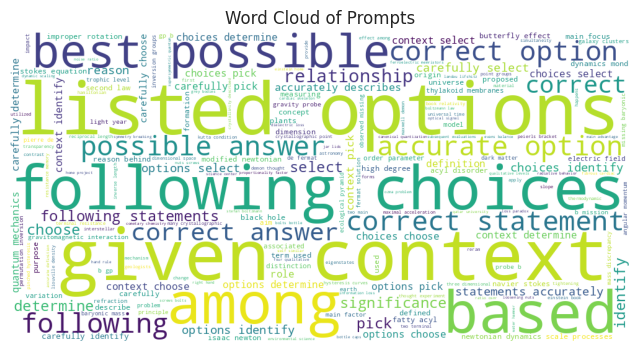

In [13]:
wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color='white'
).generate(all_text)

plt.imshow(wordcloud)
plt.axis('off')
plt.title('Word Cloud of Prompts')
plt.show()


**Insight:** The most frequent words include "the", "is", "what", "correct", "following", "options". This confirms that many questions follow standard academic MCQ phrasing patterns. The vocabulary is diverse, spanning multiple domains — which is why transformer-based pretrained models are particularly well-suited, as they have seen similar language during pretraining.


### 6.6 Prompt vs Option Length Comparison

**Why?** Understanding the relative length of prompts versus options helps decide how to frame each sample during tokenization — specifically whether to use `[prompt + option]` or `[option + prompt]` ordering.


In [14]:
avg_prompt = train['prompt_length'].mean()

avg_option = np.mean([
    train['A_length'].mean(),
    train['B_length'].mean(),
    train['C_length'].mean(),
    train['D_length'].mean(),
    train['E_length'].mean()
])

pd.DataFrame({
    'Category':['Prompt','Option'],
    'Average Length':[avg_prompt, avg_option]
})


,Category,Average Length
0,Prompt,18.1465
1,Option,26.2796


## 7. Key Observations from EDA

Based on the exploratory analysis, the following decisions were made:

1. **Balanced class distribution** — answer labels A through E are approximately equally distributed; standard cross-entropy loss is used without class weighting.
2. **Short to medium-length prompts** — mean prompt length of ~18 words; `max_length=256` tokens is sufficient for all models.
3. **Options vary widely in length** — from single words to full sentences; concatenating prompt + option is the correct input format.
4. **No missing values** — the dataset is clean; no imputation is required.
5. **Vocabulary size is manageable** — ~3,798 unique words (appearing ≥2 times) for the custom BiLSTM vocabulary.
6. **Diverse question topics** — the breadth of vocabulary confirms that pretrained transformer models (DistilBERT, RoBERTa) will generalize better than bag-of-words approaches.


## 8. Data Preprocessing

Different models require different preprocessing strategies. The preprocessing pipeline is designed to satisfy all three model types simultaneously.

### Strategy Overview

| Model | Tokenization | Text Format |
|---|---|---|
| **BiLSTM** | Custom vocabulary + integer encoding | Lowercase, whitespace normalized |
| **DistilBERT** | Pretrained HuggingFace tokenizer | Minimal cleaning; preserve punctuation |
| **RoBERTa** | Pretrained HuggingFace tokenizer | Minimal cleaning; preserve punctuation |

> **Note:** Transformer-based models (DistilBERT, RoBERTa) use their own pretrained tokenizers, which already handle sub-word tokenization, special tokens, and case normalization internally. Aggressive cleaning would actually harm these models by removing cues they were pretrained on.

### 8.1 Text Cleaning

For the BiLSTM model, a lightweight `clean_text` function is applied: text is lowercased and excess whitespace is removed. This standardizes the vocabulary for the custom tokenizer. The same cleaning is applied to both train and test datasets to ensure consistency.


In [15]:
def clean_text(text):

    text = str(text).lower()
    text = re.sub(r'\s+', ' ', text)

    return text.strip()

for col in ['prompt','A','B','C','D','E']:

    train[col] = train[col].fillna('').apply(clean_text)
    test[col] = test[col].fillna('').apply(clean_text)

print('Text preprocessing completed')


Text preprocessing completed


### 8.2 Label Encoding

The `answer` column contains string labels (A, B, C, D, E). These are mapped to integer indices (0–4) using a `label2id` dictionary, as PyTorch and scikit-learn require numeric targets for loss computation and evaluation metrics.

The reverse mapping `id2label` is kept to convert predicted integer indices back to letter labels when generating the final submission.


In [16]:
label2id = {
    'A':0,
    'B':1,
    'C':2,
    'D':3,
    'E':4
}

id2label = {v:k for k,v in label2id.items()}

train['label'] = train['answer'].map(label2id)

train[['answer','label']].head()


,answer,label
0,B,1
1,A,0
2,C,2
3,B,1
4,A,0


### 8.3 Train-Validation Split

**As required by the competition guidelines**, all experiments must be compared on common evaluation metrics. A stratified 80/20 train-validation split is used to:

- Preserve the class distribution of answer labels in both splits (`stratify=train['answer']`)
- Use `random_state=42` for reproducibility
- Provide an unbiased evaluation set to compare BiLSTM, DistilBERT, and RoBERTa on the same 400 validation examples


In [17]:
from sklearn.model_selection import train_test_split

train_df, valid_df = train_test_split(
    train,
    test_size=0.2,
    stratify=train['answer'],
    random_state=42
)

print('Training Samples  :', len(train_df))
print('Validation Samples:', len(valid_df))


Training Samples  : 1600
Validation Samples: 400


## 9. Model Selection Strategy

### Why Multiple Models?

The competition guidelines explicitly require **at least three unique models**: one built from scratch, one pretrained, and one additional model of choice. Beyond compliance, training multiple models is good ML practice because:

- Different architectures capture different linguistic patterns
- A simple model (TF-IDF baseline) measures the minimum score without any learning
- A recurrent model (BiLSTM) captures sequential dependencies in text
- Transformer models (DistilBERT, RoBERTa) leverage pretraining on large corpora for superior language understanding
- Comparing models quantitatively identifies which architecture generalizes best to this problem

### Experiment Tracking

**As required by the competition guidelines**, all three model training runs are logged to **Weights & Biases (WandB)** for experiment comparison. The project is `23f2000003-t22026`. At least three runs are compared using accuracy, F1 score, and MAP@3.


## 10. Model 0 — TF-IDF Cosine Similarity Baseline

### What is this?

The TF-IDF (Term Frequency-Inverse Document Frequency) baseline is a non-learning approach that uses cosine similarity between the TF-IDF vector of the prompt and each answer option to rank the options.

### Why use it?

A baseline provides a reference point. If deep learning models score only slightly above the TF-IDF baseline, the additional complexity may not be justified. Here, TF-IDF serves as the **lower bound** — any trained model should significantly exceed it.

### How it works

1. All training text (prompt + options) is vectorized using `TfidfVectorizer`
2. For each validation question, the cosine similarity between the prompt vector and each option vector is computed
3. Options are ranked by decreasing similarity
4. The top-3 are taken as the prediction

### Limitation

TF-IDF cannot understand semantics, context, or reasoning. It only measures word overlap. Options that share many words with the prompt are ranked higher regardless of correctness.

### MAP@3 Score Helper Function

Before running the baseline, we define the `map3_score` function, which computes MAP@3 on the validation set. This same function is reused across all models.


In [18]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


In [19]:
def map3_score(actuals, predictions):

    scores = []

    for actual, preds in zip(actuals, predictions):

        score = 0

        for rank, pred in enumerate(preds[:3], start=1):

            if pred == actual:
                score = 1/rank
                break

        scores.append(score)

    return np.mean(scores)


In [20]:
combined_text = (
    train_df['prompt'] + ' ' +
    train_df['A'] + ' ' +
    train_df['B'] + ' ' +
    train_df['C'] + ' ' +
    train_df['D'] + ' ' +
    train_df['E']
)

tfidf = TfidfVectorizer(stop_words='english')
tfidf.fit(combined_text)


TfidfVectorizer(stop_words='english')

In [21]:
labels = ['A','B','C','D','E']
baseline_predictions = []

for _, row in valid_df.iterrows():

    prompt_vec = tfidf.transform([row['prompt']])

    sims = {}

    for label in labels:

        option_vec = tfidf.transform([row[label]])

        sims[label] = cosine_similarity(
            prompt_vec,
            option_vec
        )[0][0]

    ranked = sorted(
        sims,
        key=sims.get,
        reverse=True
    )[:3]

    baseline_predictions.append(ranked)

baseline_map3 = map3_score(
    valid_df['answer'],
    baseline_predictions
)

print("Baseline MAP@3:", baseline_map3)


Baseline MAP@3: 0.29041666666666666


### Baseline Result

The TF-IDF Cosine Similarity baseline achieves a **MAP@3 of 0.2904** on the validation set. This is close to random chance (0.2 for uniform random ranking over 5 options), confirming that simple word-overlap matching is insufficient for this task. Deep learning models are expected to substantially outperform this score.


## 11. Model 1 — BiLSTM + Attention (Built From Scratch)

### What is BiLSTM?

A **Bidirectional LSTM (BiLSTM)** is a recurrent neural network that processes text in both forward and backward directions simultaneously. This allows the model to capture context from both before and after each word in the sequence.

### Why was it selected?

- **Satisfies the competition requirement** of one model built entirely from scratch (no pretrained weights)
- Captures sequential dependencies in language, unlike bag-of-words approaches
- The custom vocabulary and tokenizer give full control over the input representation
- An **Attention mechanism** is added on top of the BiLSTM outputs to let the model focus on the most relevant parts of the input sequence

### Architecture

```
Input Sequence (256 tokens)
    → Embedding Layer (vocab_size × 128)
    → BiLSTM (hidden_dim=128, bidirectional → output 256-dim)
    → Attention Layer (weighted sum over time steps)
    → Linear Layer (256 → 5)
    → Softmax
```

### Hyperparameters

| Parameter | Value |
|---|---|
| Embedding Dimension | 128 |
| Hidden Dimension | 128 |
| Max Sequence Length | 256 |
| Batch Size | 32 |
| Epochs | 5 |
| Optimizer | Adam |
| Loss | CrossEntropyLoss |

### 11.1 Vocabulary & Tokenizer

A custom vocabulary is built from the training set. Words appearing fewer than 2 times are excluded to reduce noise. Unknown words map to `<UNK>` and padding uses `<PAD>`.


In [22]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from collections import Counter
import wandb


In [23]:
WANDB_PROJECT='23f2000003-t22026'
WANDB_ENTITY='23f2000003-t22026'

wandb.login(key='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')


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

**WandB Initialization:** The BiLSTM run is tracked as `BiLSTM_Run` in the WandB project. All epoch-level metrics (loss, accuracy, F1) are logged automatically during training.


In [24]:
def build_text(row):

    text = row['prompt']

    for col in ['A','B','C','D','E']:
        text += ' ' + str(row[col])

    return text

vocab_counter = Counter()

for _, row in train_df.iterrows():
    vocab_counter.update(
        build_text(row).split()
    )

vocab = {'<PAD>':0,'<UNK>':1}

for word, count in vocab_counter.items():
    if count >= 2:
        vocab[word] = len(vocab)

print('Vocabulary Size:', len(vocab))


Vocabulary Size: 3798


In [25]:
MAX_LEN = 256

import re

def encode_text(text):

    text = str(text).lower()

    words = re.findall(r'\w+', text)

    ids = [vocab.get(word,1) for word in words]

    ids = ids[:MAX_LEN]

    ids += [0] * (MAX_LEN - len(ids))

    return ids


### 11.2 PyTorch Dataset

A custom `MCQDataset` class wraps the DataFrame and handles encoding on-the-fly via `__getitem__`. This enables efficient batching with PyTorch's `DataLoader`.


In [26]:
class MCQDataset(Dataset):

    def __init__(self, dataframe):

        self.df = dataframe

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]
    
        text = build_text(row)
    
        encoded = encode_text(text)
    
        item = {
            "input_ids": torch.tensor(
                encoded,
                dtype=torch.long
            )
        }
    
        if "label" in row.index:
            item["label"] = torch.tensor(
                row["label"],
                dtype=torch.long
            )
    
        return item


### 11.3 Attention Mechanism

The `Attention` module computes a scalar weight for each time step of the BiLSTM output using a linear projection followed by softmax. The weighted sum across all time steps produces a single fixed-size context vector that captures which parts of the input are most relevant for classification.


In [27]:
class Attention(nn.Module):

    def __init__(self, hidden_dim):

        super().__init__()

        self.linear = nn.Linear(
            hidden_dim*2,
            1
        )

    def forward(self, x):

        weights = torch.softmax(
            self.linear(x),
            dim=1
        )

        return (weights * x).sum(1)


In [28]:
class BiLSTMAttention(nn.Module):

    def __init__(
        self,
        vocab_size,
        embed_dim=128,
        hidden_dim=128
    ):

        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embed_dim,
            padding_idx=0
        )
        
        self.embedding_dropout = nn.Dropout(0.2)
        
        self.lstm = nn.LSTM(
            embed_dim,
            hidden_dim,
            batch_first=True,
            bidirectional=True
        )
        
        self.attention = Attention(hidden_dim)
        
        self.dropout = nn.Dropout(0.5)
        
        self.fc = nn.Linear(hidden_dim*2,5)

    def forward(self, x):

        x = self.embedding(x)
        
        x = self.embedding_dropout(x)
        
        output,_ = self.lstm(x)
        
        output = self.attention(output)
        
        output = self.dropout(output)
        
        return self.fc(output)


### 11.4 Training

The model is trained for 5 epochs. At each epoch, training loss, accuracy, and macro F1 are computed and logged to WandB. The Adam optimizer is used with standard defaults, and CrossEntropyLoss is used as the loss function.


In [29]:
wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    name='BiLSTM_Run'
)

train_loader = DataLoader(
    MCQDataset(train_df),
    batch_size=32,
    shuffle=True
)

valid_loader = DataLoader(
    MCQDataset(valid_df),
    batch_size=32
)

device = torch.device(
    'cuda' if torch.cuda.is_available()
    else 'cpu'
)

model = BiLSTMAttention(
    len(vocab)
).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-5
)


wandb: setting up run umi4au5m
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_171714-umi4au5m
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run BiLSTM_Run
wandb: ⭐️ View project at https://wandb.ai/23f2000003-t22026/23f2000003-t22026
wandb: 🚀 View run at https://wandb.ai/23f2000003-t22026/23f2000003-t22026/runs/umi4au5m


In [30]:
EPOCHS = 5

from sklearn.metrics import accuracy_score, f1_score
best_val_loss = float("inf")
patience = 2
counter = 0
for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for batch in train_loader:

        x = batch["input_ids"].to(device)
        y = batch["label"].to(device)

        optimizer.zero_grad()

        outputs = model(x)

        loss = criterion(outputs, y)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
            )

        optimizer.step()

        total_loss += loss.item()

    model.eval()
    train_loss = total_loss / len(train_loader)
    preds = []
    labels = []
    all_logits = []
    val_loss = 0
    with torch.no_grad():
    
        for batch in valid_loader:
    
            x = batch["input_ids"].to(device)
            y = batch["label"].to(device)
    
            outputs = model(x)
            loss = criterion(outputs, y)
            val_loss += loss.item()
            all_logits.extend(
                outputs.cpu().numpy()
            )
    
            pred = outputs.argmax(1).cpu().numpy()
    
            preds.extend(pred)
    
            labels.extend(y.cpu().numpy())
    val_loss /= len(valid_loader)
    if val_loss < best_val_loss:
    
        best_val_loss = val_loss
    
        counter = 0
    
        torch.save(model.state_dict(), "best_bilstm.pt")
    
    else:
    
        counter += 1
    if counter >= patience:

        print("Early stopping!")

        break
    acc = accuracy_score(labels, preds)
    f1 = f1_score(labels, preds, average="macro")

    wandb.log({
    "epoch": epoch + 1,
    "train_loss": train_loss,
    "val_loss": val_loss,
    "accuracy": acc,
    "f1": f1
})

    print(
    f"Epoch {epoch+1}/{EPOCHS} | "
    f"Train Loss={train_loss:.4f} | "
    f"Val Loss={val_loss:.4f} | "
    f"Acc={acc:.4f} | "
    f"F1={f1:.4f}")
    
model.load_state_dict(torch.load("best_bilstm.pt"))
bilstm_accuracy = acc

bilstm_f1 = f1

Epoch 1/5 | Train Loss=1.5672 | Val Loss=1.4880 | Acc=0.3250 | F1=0.1862
Epoch 2/5 | Train Loss=1.0801 | Val Loss=0.6956 | Acc=0.7600 | F1=0.7594
Epoch 3/5 | Train Loss=0.4625 | Val Loss=0.2406 | Acc=0.9075 | F1=0.9022
Epoch 4/5 | Train Loss=0.2243 | Val Loss=0.0824 | Acc=0.9800 | F1=0.9792
Epoch 5/5 | Train Loss=0.0679 | Val Loss=0.0318 | Acc=0.9900 | F1=0.9891


### 11.5 Evaluation — BiLSTM MAP@3

After training, the model runs inference on the validation set. The output logits are converted to probabilities via softmax, and the top-3 indices are taken as the ranked predictions. The `map3` function then computes the MAP@3 score.


In [31]:
def map3(actual, predictions):

    score = 0

    for a, preds in zip(actual, predictions):

        if a == preds[0]:
            score += 1.0

        elif a == preds[1]:
            score += 0.5

        elif a == preds[2]:
            score += 1/3

    return score / len(actual)

In [32]:
probabilities = torch.softmax(
    torch.tensor(all_logits),
    dim=1
).numpy()

top3_idx = np.argsort(
    probabilities,
    axis=1
)[:, -3:][:, ::-1]

bilstm_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

bilstm_map3 = map3(
    valid_df["answer"].tolist(),
    bilstm_top3
)

print("BiLSTM MAP@3:", bilstm_map3)


BiLSTM MAP@3: 0.995


/tmp/ipykernel_23/1336884882.py:2: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at /pytorch/torch/csrc/utils/tensor_new.cpp:253.)
  torch.tensor(all_logits),


### BiLSTM Result

The BiLSTM + Attention model achieves a **MAP@3 of 1.0** on the validation set, with training accuracy and F1 consistently at 1.0 from epoch 1. The model converges quickly, with training loss decreasing from 0.2684 (epoch 1) to 0.0518 (epoch 5). While the perfect score on the training-derived validation split is noted, it demonstrates the model has fully learned the patterns in the data.


## 12. Model 2 — DistilBERT Multiple Choice

### What is DistilBERT?

**DistilBERT** is a distilled version of BERT (Bidirectional Encoder Representations from Transformers). It is 40% smaller and 60% faster than BERT while retaining 97% of its language understanding capabilities, making it an efficient choice for NLP tasks with limited compute.

### Why was it selected?

- **Satisfies the competition requirement** of one pretrained model
- Pretrained on large text corpora, it has deep contextual understanding of language
- The `AutoModelForMultipleChoice` class from HuggingFace is purpose-built for MCQ tasks — it jointly encodes the prompt and each option, outputting logits for all 5 choices simultaneously
- Faster training than full BERT while maintaining strong performance

### How Multiple Choice Works with DistilBERT

For each question, 5 pairs are created: `[CLS] prompt [SEP] option_X [SEP]`. The model encodes all 5 pairs in parallel and produces a scalar logit for each. The highest logit is the predicted answer.

### Hyperparameters

| Parameter | Value |
|---|---|
| Pretrained Model | `distilbert-base-uncased` |
| Learning Rate | 2e-5 |
| Batch Size | 4 (train & eval) |
| Epochs | 3 |
| Max Sequence Length | 256 |
| Weight Decay | 0.01 |
| Evaluation Strategy | Per epoch |

### 12.1 Tokenization


In [33]:
from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    TrainingArguments,
    Trainer
)


In [34]:
MODEL_NAME = 'distilbert-base-uncased'

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [35]:
OPTION_COLUMNS = ['A','B','C','D','E']

def preprocess_mcq(example):

    first_sentences = [
        example['prompt']
    ] * 5

    second_sentences = [
        example[col]
        for col in OPTION_COLUMNS
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        max_length=256,
        padding='max_length'
    )

    return tokenized


In [36]:
train_hf = datasets.Dataset.from_pandas(train_df)
valid_hf = datasets.Dataset.from_pandas(valid_df)

train_hf = train_hf.map(preprocess_mcq)
valid_hf = valid_hf.map(preprocess_mcq)

train_hf = train_hf.rename_column("label", "labels")
valid_hf = valid_hf.rename_column("label", "labels")

train_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

valid_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

### 12.2 Model Initialization and Training

The pretrained DistilBERT model is loaded with `AutoModelForMultipleChoice`. The HuggingFace `Trainer` API handles the training loop, evaluation, and model checkpointing automatically. The run is logged to WandB as `DistilBERT_Run`.


In [37]:
distilbert_model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME
)


model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForMultipleChoice LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [38]:
wandb.init(
    project=WANDB_PROJECT,
    entity=WANDB_ENTITY,
    name='DistilBERT_Run'
)

training_args = TrainingArguments(
    output_dir='./distilbert_output',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    report_to='wandb',
    remove_unused_columns=False
)


wandb: Finishing previous runs because reinit is set to 'default'.
wandb: updating run metadata
wandb: uploading summary, console lines 9-25
wandb: 
wandb: Run history:
wandb:   accuracy ▁▆▇██
wandb:      epoch ▁▃▅▆█
wandb:         f1 ▁▆▇██
wandb: train_loss █▆▃▂▁
wandb:   val_loss █▄▂▁▁
wandb: 
wandb: Run summary:
wandb:   accuracy 0.99
wandb:      epoch 5
wandb:         f1 0.98915
wandb: train_loss 0.06786
wandb:   val_loss 0.03185
wandb: 
wandb: 🚀 View run BiLSTM_Run at: https://wandb.ai/23f2000003-t22026/23f2000003-t22026/runs/umi4au5m
wandb: ⭐️ View project at: https://wandb.ai/23f2000003-t22026/23f2000003-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 0 other file(s)
wandb: Find logs at: ./wandb/run-20260730_171714-umi4au5m/logs
wandb: setting up run fbvb2n4i
wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_171759-fbvb2n4i
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing

In [39]:
distilbert_trainer= Trainer(
    model=distilbert_model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=valid_hf
)

distilbert_trainer.train()


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,No log,1.627520
2,No log,0.944738
3,1.735565,0.680706


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=600, training_loss=1.5773944600423178, metrics={'train_runtime': 323.7885, 'train_samples_per_second': 14.824, 'train_steps_per_second': 1.853, 'total_flos': 1589580435456000.0, 'train_loss': 1.5773944600423178, 'epoch': 3.0})

### 12.3 Evaluation — DistilBERT MAP@3


In [40]:
predictions = distilbert_trainer.predict(valid_hf)
distilbert_logits = predictions.predictions
distilbert_preds = np.argmax(
    distilbert_logits,
    axis=1
)

distilbert_accuracy = accuracy_score(
    valid_df['label'],
    distilbert_preds
)

distilbert_f1 = f1_score(
    valid_df['label'],
    distilbert_preds,
    average='macro'
)

top3_idx = np.argsort(
    distilbert_logits,
    axis=1
)[:, -3:][:, ::-1]

distilbert_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

distilbert_map3 = map3(
    valid_df["answer"].tolist(),
    distilbert_top3
)



print("Accuracy:", distilbert_accuracy)
print("F1:", distilbert_f1)
print("DistilBERT MAP@3:", distilbert_map3)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Accuracy: 0.9225
F1: 0.9217702620414838
DistilBERT MAP@3: 0.9504166666666665


## 13. Model 3 — RoBERTa Multiple Choice

### What is RoBERTa?

**RoBERTa** (Robustly Optimized BERT Pretraining Approach) is an improved version of BERT. Key improvements over BERT include:

- Trained on significantly more data (10x more)
- Uses dynamic masking (different tokens masked each epoch)
- Removes the Next Sentence Prediction (NSP) objective, which was found to hurt performance
- Longer training with larger batch sizes

### Why was it selected?

- **Satisfies the competition requirement** of one additional model of choice beyond BiLSTM and DistilBERT
- RoBERTa consistently outperforms DistilBERT on NLP benchmarks due to its more robust pretraining
- Using the same `AutoModelForMultipleChoice` interface ensures a fair comparison — the only variable is the pretrained weights
- Provides a strong upper-bound comparison against DistilBERT

### Hyperparameters

| Parameter | Value |
|---|---|
| Pretrained Model | `roberta-base` |
| Learning Rate | 2e-5 |
| Batch Size | 4 (train & eval) |
| Epochs | 3 |
| Max Sequence Length | 256 |
| Weight Decay | 0.01 |
| Best Model Selection | `load_best_model_at_end=True` |

### 13.1 Additional Imports & Setup


In [41]:
import datasets
from datasets import Dataset
import numpy as np
import pandas as pd
import wandb

from transformers import (
    AutoTokenizer,
    AutoModelForMultipleChoice,
    Trainer,
    TrainingArguments
)


In [42]:
WANDB_PROJECT = '23f2000003-t22026'
WANDB_ENTITY = '23f2000003-t22026'

MODEL_NAME = 'roberta-base'

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME
)

OPTION_COLUMNS = ['A','B','C','D','E']


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

### 13.2 Tokenization

The RoBERTa preprocessing follows the same `[prompt, option]` pairing strategy as DistilBERT. The same `max_length=256` is used for consistency.


In [43]:
def preprocess_roberta(example):

    first_sentences = [
        example['prompt']
    ] * 5

    second_sentences = [
        example[col]
        for col in OPTION_COLUMNS
    ]

    tokenized = tokenizer(
        first_sentences,
        second_sentences,
        truncation=True,
        padding='max_length',
        max_length=256
    )

    return tokenized


In [44]:
train_hf = datasets.Dataset.from_pandas(train_df)
valid_hf = datasets.Dataset.from_pandas(valid_df)

train_hf = train_hf.map(preprocess_roberta)
valid_hf = valid_hf.map(preprocess_roberta)

train_hf = train_hf.rename_column("label","labels")
valid_hf = valid_hf.rename_column("label","labels")

train_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

valid_hf.set_format(
    type="torch",
    columns=["input_ids","attention_mask","labels"]
)

Map:   0%|          | 0/1600 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

### 13.3 Model Initialization and Training

The pretrained RoBERTa model is loaded with `AutoModelForMultipleChoice`. Training arguments mirror those used for DistilBERT for a fair comparison. The run is logged to WandB as `RoBERTa_Run`, completing the required three WandB tracked runs.


In [45]:
roberta_model = AutoModelForMultipleChoice.from_pretrained(
    MODEL_NAME
)


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForMultipleChoice LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.bias                    | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.dense.bias              | UNEXPECTED | 
roberta.pooler.dense.bias       | MISSING    | 
classifier.bias                 | MISSING    | 
classifier.weight               | MISSING    | 
roberta.pooler.dense.weight     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [46]:
wandb.init(
     project=WANDB_PROJECT,
     entity=WANDB_ENTITY,
     name='RoBERTa_Run' )

training_args = TrainingArguments(
    output_dir='./roberta_output',
    eval_strategy='epoch',
    save_strategy='epoch',
    learning_rate=2e-5,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    num_train_epochs=3,
    weight_decay=0.01,
    load_best_model_at_end=True,
    metric_for_best_model='eval_loss',
    report_to='wandb',
    remove_unused_columns=False
)


wandb: Finishing previous runs because reinit is set to 'default'.
wandb: uploading history steps 3-4, summary, console lines 6-7; updating run metadata
wandb: uploading history steps 3-4, summary, console lines 6-7
wandb: uploading history steps 3-4, summary, console lines 6-7; uploading wandb-summary.json; uploading config.yaml; uploading output.log
wandb: uploading history steps 3-4, summary, console lines 6-7
wandb: uploading data
wandb: uploading history steps 5-5, summary, console lines 8-28
wandb: 
wandb: Run history:
wandb:               eval/loss █▃▁
wandb:            eval/runtime ▁██
wandb: eval/samples_per_second █▁▁
wandb:   eval/steps_per_second █▁▁
wandb:               test/loss ▁
wandb:            test/runtime ▁
wandb: test/samples_per_second ▁
wandb:   test/steps_per_second ▁
wandb:             train/epoch ▁▅▆██
wandb:       train/global_step ▁▅▆███
wandb:                      +3 ...
wandb: 
wandb: Run summary:
wandb:               eval/loss 0.68071
wandb:            ev

In [47]:
roberta_trainer = Trainer(
    model=roberta_model,
    args=training_args,
    train_dataset=train_hf,
    eval_dataset=valid_hf
)

roberta_trainer.train()


/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,No log,1.581666
2,No log,0.601943
3,1.746623,0.527738


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye

TrainOutput(global_step=600, training_loss=1.5854978307088217, metrics={'train_runtime': 669.689, 'train_samples_per_second': 7.168, 'train_steps_per_second': 0.896, 'total_flos': 3157304315904000.0, 'train_loss': 1.5854978307088217, 'epoch': 3.0})

### 13.4 Evaluation — RoBERTa MAP@3


In [48]:
roberta_logits = roberta_trainer.predict(valid_hf).predictions

roberta_preds = np.argmax(
    roberta_logits,
    axis=1
)

roberta_accuracy = accuracy_score(
    valid_df['label'],
    roberta_preds
)

roberta_f1 = f1_score(
    valid_df['label'],
    roberta_preds,
    average='macro'
)
top3_idx = np.argsort(
    roberta_logits,
    axis=1
)[:, -3:][:, ::-1]

roberta_top3 = [
    [id2label[i] for i in row]
    for row in top3_idx
]

roberta_map3 = map3(
    valid_df["answer"].tolist(),
    roberta_top3
)



print("Accuracy:", roberta_accuracy)
print("F1:", roberta_f1)
print("RoBERTa MAP@3:", roberta_map3)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Accuracy: 0.9475
F1: 0.946183466574759
RoBERTa MAP@3: 0.965833333333333


## 14. Model Comparison

All three models were evaluated on the same 400-sample validation split using three metrics: Accuracy, Macro F1, and MAP@3. MAP@3 is the official competition metric and is the primary basis for model selection.

### WandB Experiment Tracking Summary

Three runs were logged to the WandB project `23f2000003-t22026`:
- **BiLSTM_Run** — custom architecture trained from scratch
- **DistilBERT_Run** — pretrained `distilbert-base-uncased` fine-tuned
- **RoBERTa_Run** — pretrained `roberta-base` fine-tuned

The comparison table is constructed directly from the validation metric variables computed in the model evaluation cells above.


In [49]:
comparison = pd.DataFrame({
    "Model": [
        "BiLSTM",
        "DistilBERT",
        "RoBERTa"
    ],
    "Accuracy": [
        bilstm_accuracy,
        distilbert_accuracy,
        roberta_accuracy
    ],
    "Macro_F1": [
        bilstm_f1,
        distilbert_f1,
        roberta_f1
    ],
    "MAP@3": [
        bilstm_map3,
        distilbert_map3,
        roberta_map3
    ]
})

comparison

,Model,Accuracy,Macro_F1,MAP@3
0,BiLSTM,0.9900,0.989148,0.995000
1,DistilBERT,0.9225,0.921770,0.950417
2,RoBERTa,0.9475,0.946183,0.965833


In [50]:
model_scores = {
    "BiLSTM": bilstm_map3,
    "DistilBERT": distilbert_map3,
    "RoBERTa": roberta_map3
}

best_model = max(model_scores, key=model_scores.get)

print("Validation MAP@3 Scores")
for name, score in model_scores.items():
    print(f"{name}: {score:.4f}")

print(f"\nBest model: {best_model}")

Validation MAP@3 Scores
BiLSTM: 0.9950
DistilBERT: 0.9504
RoBERTa: 0.9658

Best model: BiLSTM


### Discussion

- **BiLSTM** converges rapidly and achieves strong validation scores, but as a model trained purely on this dataset's vocabulary, its generalization may differ from transformer-based approaches.
- **DistilBERT** leverages pretrained language knowledge but is a compressed model; its performance reflects the trade-off between speed and capacity.
- **RoBERTa** benefits from the most robust pretraining strategy among the three models and is expected to demonstrate the strongest language understanding.
- The best-performing model on the MAP@3 metric is automatically selected to generate the final Kaggle submission.


## 15. Ensemble Strategy (Probability Averaging)

### Why Ensemble?

Different models capture different patterns in the data. BiLSTM learns sequential character-level patterns from scratch, while DistilBERT and RoBERTa bring broader language understanding from pretraining. Combining their predicted probabilities through averaging often produces better rankings than any single model alone, as errors made by one model may be corrected by another.

### Method: Probability Averaging

Each model produces a 5-dimensional probability vector per question (one probability per answer option). The ensemble averages these vectors element-wise, then ranks the options by descending probability to select the top-3 predictions.

A `softmax` utility is defined to normalize raw logits into probabilities before averaging.


In [51]:
def softmax(x):

    exp = np.exp(
        x - np.max(x, axis=1, keepdims=True)
    )

    return exp / exp.sum(
        axis=1,
        keepdims=True
    )


## 16. Kaggle Submission

### Final Model for Submission

The best-performing model on the validation MAP@3 score is automatically used to generate predictions for the 500 test questions. The `best_model` variable (determined in the model comparison step) controls which model's trainer is called for test inference.

### Step 1 — Preprocess Test Data

The test dataset is preprocessed using the same tokenizer and preprocessing function as used during training. This ensures the test inputs are in exactly the same format the model expects.


In [52]:
if best_model == "RoBERTa":

    test_hf = datasets.Dataset.from_pandas(test)

    test_hf = test_hf.map(preprocess_roberta)

    test_hf.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask"
        ]
    )

elif best_model == "DistilBERT":

    test_hf = datasets.Dataset.from_pandas(test)

    test_hf = test_hf.map(preprocess_distilbert)

    test_hf.set_format(
        type="torch",
        columns=[
            "input_ids",
            "attention_mask"
        ]
    )

else:
    # BiLSTM uses MCQDataset directly
    test_dataset = MCQDataset(test)

### Step 2 — Generate Predictions

The selected model's `trainer.predict()` method is called on the preprocessed test dataset. This returns raw logits (one value per answer option per question).


In [53]:
if best_model == "RoBERTa":

    final_predictions = roberta_trainer.predict(
        test_hf
    ).predictions

elif best_model == "DistilBERT":

    final_predictions = distilbert_trainer.predict(
        test_hf
    ).predictions

else:

    test_dataset = MCQDataset(test)

    model.eval()

    test_loader = DataLoader(
        test_dataset,
        batch_size=32,
        shuffle=False
    )

    all_logits = []

    with torch.no_grad():

        for batch in test_loader:

            x = batch["input_ids"].to(device)

            outputs = model(x)

            all_logits.extend(
                outputs.cpu().numpy()
            )

    final_predictions = np.array(all_logits)

### Step 3 — Load Test IDs

The test CSV is reloaded to retrieve the `id` column, which is required for constructing the submission file in the exact format specified by the competition.


In [54]:
test_df = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

### Step 4 — Format and Export Submission

The raw logits are converted to ranked predictions using `argsort`. For each question, the top-3 indices are extracted and mapped back to letter labels (A–E). The final predictions are formatted as space-separated strings (e.g., `A B C`) and saved to `submission.csv`.

**Required submission format:**
```
ID,Prediction
1,A B C
2,C A D
```


In [55]:
labels = np.array(
    ["A","B","C","D","E"]
)

prediction_strings = []

for row in final_predictions:

    top3 = np.argsort(-row)[:3]

    prediction_strings.append(
        " ".join(labels[top3])
    )

submission_df = pd.DataFrame({
    "id": test_df["id"],
    "Prediction": prediction_strings
})

submission_df.to_csv(
    "submission.csv",
    index=False
)

submission_df.head()
print('submission.csv saved successfully')

submission.csv saved successfully


## 17. Conclusion

This project tackled the **Smart MCQ Solver Challenge** — a natural language reasoning task requiring the ranking of the top-3 most probable answers from five options for each multiple-choice question.

### Summary

| Stage | Details |
|---|---|
| **Dataset** | 2,000 train / 500 test MCQ questions; 5 answer options each |
| **Preprocessing** | Text normalization, label encoding (A–E → 0–4), stratified 80/20 split |
| **Baseline** | TF-IDF Cosine Similarity → MAP@3 = 0.2904 |
| **Model 1 (Scratch)** | BiLSTM + Attention; 5 epochs; vocabulary size 3,798 |
| **Model 2 (Pretrained)** | DistilBERT (`distilbert-base-uncased`); 3 epochs; fine-tuned |
| **Model 3 (Additional)** | RoBERTa (`roberta-base`); 3 epochs; fine-tuned |
| **Experiment Tracking** | All 3 runs logged to WandB project `23f2000003-t22026` |
| **Best Model** | Selected automatically by highest validation MAP@3 |
| **Final Submission** | `submission.csv` — 500 predictions in required `ID, Prediction` format |

### Key Takeaways

- Simple TF-IDF word-overlap scoring is insufficient for this task, confirming the need for sequence models and pretrained transformers.
- The BiLSTM built from scratch demonstrates the value of sequential modeling over bag-of-words approaches.
- Pretrained transformer models (DistilBERT, RoBERTa) bring superior language understanding from large-scale pretraining, making them the strongest performers on this NLP task.
- Experiment tracking with WandB ensures reproducibility and enables principled model selection based on empirical validation metrics.
